# Sri Lankan Used Vehicle Listing Price Prediction
## Comparing regression models with group-aware validation

MSc Machine Learning final assignment. This project extends an earlier class activity with a separate implementation, grouped evaluation, bounded tuning and categorical boosting. It predicts historical advertised listing prices, rather than sale prices or current market values.

**Research questions**
1. How do a median baseline, Ridge, Random Forest, XGBoost and CatBoost compare under grouped validation?
2. How sensitive are fixed model configurations to random versus grouped splitting?
3. Which vehicle attributes support prediction, and where do errors remain large?

The original activity is a read-only reference. All outputs from this notebook stay in this assignment directory.

## 1. Reproducibility and execution
Use Python 3.12 and the project's `.venv`, with the assignment root as the working directory. A normal Run All creates a new experiment, fits the baselines, performs the bounded search, refits models and evaluates them. Accepted outputs are not replaced. Searches are sequential, estimators use two threads, and one-hot matrices remain sparse.

The supporting implementation is kept in `src/`. The notebook presents its inputs, decisions and measured outputs rather than repeating long function definitions. The main workflow is:

| Function | Module | What it does and returns |
|---|---|---|
| `load_data()` | `src/data.py` | Verifies the version-3 checksum and schema, removes exact duplicates and returns the cleaned dataframe. |
| `make_splits(data)` | `src/data.py` | Returns development/test row indices and five development-only group folds. |
| `audit_and_split(RUN_DIR)` | `src/training.py` | Records the deterministic audit and split assignments in a new run; returns data, development indices, test indices and folds. |
| `make_model(name, params)` | `src/models.py` | Builds an unfitted pipeline with model-specific preprocessing; fitting occurs only on the training rows supplied later. |
| `development_eda(RUN_DIR)` | `src/reporting.py` | Summarizes development rows and saves EDA figures; returns the summary. |
| `pilot(RUN_DIR)` | `src/training.py` | Fits small development subsets and records timing/memory diagnostics, or reads that run's existing pilot record. |
| `tune(RUN_DIR)` | `src/training.py` | Fits each candidate on the same five group folds, records validation scores, and returns the CV-only selection. Completed folds can be resumed under an unchanged run signature. |
| `evaluate(RUN_DIR)` | `src/training.py` | Refits family winners on development data, scores the reserved test rows, exports/reloads pipelines, and records fixed-setting sensitivity and interpretation. It returns the five-model test table without changing the selected family. |
| `metrics(y, prediction)` | `src/training.py` | Calculates MAE, RMSE and R² in the reporting cells. |

The stored outputs are from the completed local experiment. On **23 October 2026**, only Markdown and verbose progress-output presentation were edited; no code cell was rerun or changed. Original execution counts, code, tables and image outputs are retained. Full original tuning/evaluation streams are archived in `verification/notebook_progress_original.txt`. Detailed run/resumption provenance is in `VERIFICATION.md`; setup and dataset acquisition are in `README.md` and `data/README.md`.


In [1]:
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[variable] = "2"
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from src.data import ROOT, FEATURES, NUMERIC, CATEGORICAL, load_data, make_splits, predictor_groups
from src.models import NAMES, REFERENCE_PARAMS, make_model, candidate_parameters
from src.training import new_run, prepare_run, audit_and_split, pilot, tune, evaluate, metrics, environment
from src.reporting import development_eda
assert Path.cwd().resolve() == ROOT
# Leave None for a fresh academic experiment; an explicit resume reuses checkpoints.
RESUME_RUN = os.environ.get("ASSIGNMENT_RESUME_RUN") or None
RUN_DIR = ROOT / RESUME_RUN if RESUME_RUN else new_run("notebook")
RUN_DIR = prepare_run(RUN_DIR)
print("Experiment:", RUN_DIR.relative_to(ROOT))
display(environment())

Experiment: results\runs\main-local-20261020-v2


{'python': '3.12.10',
 'platform': 'Windows-10-10.0.19045-SP0',
 'logical_cpus': 4,
 'total_ram_gb': 7.876857757568359,
 'versions': {'numpy': '2.1.3',
  'pandas': '2.2.3',
  'scipy': '1.18.1',
  'scikit-learn': '1.6.1',
  'xgboost': '3.4.1',
  'catboost': '1.2.10',
  'streamlit': '1.65.0',
  'joblib': '1.6.0',
  'psutil': '7.2.2'}}

## 2. Dataset source and scope
The dataset is Prasad Nirmal's [SriLankan Vehicle(Car) Price Dataset, version 3](https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset). The earlier activity records ikman.lk and Riyasewana.com as the listing sources. Its recorded coverage is 3 December 2024 to 5 February 2025.

The locally copied CSV is verified against SHA256 `4208d2673cf4d9c8d3d6042dc8a1b97004671812441975f5879550059fbce1ab`. No dataset download or source-activity write occurs during execution. Kaggle's page did not expose readable metadata during this review; the earlier project's MIT licence record is not a newly verified licence assertion. Raw data is excluded from Git.

The currency scale is unresolved. We retain the original values and label both predictions and errors as **dataset price units**. We make no rupee/lakh conversion.

In [2]:
data, dev, test, folds = audit_and_split(RUN_DIR)
audit = json.loads((RUN_DIR / "audit.json").read_text())
display(pd.Series({k: audit[k] for k in ["original_rows", "cleaned_rows", "exact_duplicates_removed", "predictor_groups", "duplicate_predictor_rows", "conflicting_price_groups", "mileage_formula_matches"]}))

original_rows               9788
cleaned_rows                9770
exact_duplicates_removed      18
predictor_groups            8912
duplicate_predictor_rows     858
conflicting_price_groups     479
mileage_formula_matches     9770
dtype: int64

## 3. Data quality and deterministic cleaning
The exported index is a row identifier, not a vehicle feature. Removing it reveals 18 exact duplicate records. We remove these before splitting, leaving 9,770 records. There are no missing values in this exact CSV. Numeric predictors and targets must be finite, and prices must be positive.

Every cleaned mileage value matches `(2025 - YOM) * 11000`. This establishes redundancy, not target leakage by itself. Mileage is excluded because it supplies no independent odometer measurement. Listing date is retained for audit but excluded from predictors. Repeated predictor combinations with differing prices are retained: identical recorded attributes do not necessarily identify the same physical vehicle.

No high-price trimming, speculative typo repair, target imputation or price rescaling is performed. Defensive feature imputation is still included inside each fold.

In [3]:
assert len(data) == 9770
assert not data.isna().any().any()
assert np.isclose(data["Millage(KM)"], (2025-data.YOM)*11000).all()
assert len(FEATURES) == 13
assert not {"Price", "Date", "Millage(KM)", "Unnamed: 0"}.intersection(FEATURES)
display(pd.DataFrame({"type": data.dtypes.astype(str), "missing": data.isna().sum()}))

,type,missing
Brand,object,0
Model,object,0
YOM,int64,0
Engine (cc),float64,0
Gear,object,0
Fuel Type,object,0
Millage(KM),float64,0
Town,object,0
Date,object,0
Leasing,object,0


## 4. Primary holdout and group-aware cross-validation
A group is the exact tuple of the 13 predictors; target, listing date and row position do not enter the group key. GroupShuffleSplit reserves 20% of groups with seed 42. This yields an approximately 80/20 **row** split, because groups have different sizes. Five-fold GroupKFold is applied only to development data.

The question is performance on previously unseen combinations of recorded attributes. Groups are not verified vehicle identities, and near-duplicates can remain. Hashes are used as compact group keys; tests verify their one-to-one correspondence with actual feature tuples.

All models use the same folds. Test targets do not select features, hyperparameters or the winner. The full dataset was explored in a previous activity; this is a reserved experimental holdout, not independent external validation.

In [4]:
groups = predictor_groups(data)
assert not set(groups.iloc[dev]).intersection(groups.iloc[test])
for a, b in folds:
    assert not set(groups.iloc[dev[a]]).intersection(groups.iloc[dev[b]])
display(json.loads((RUN_DIR / "split_summary.json").read_text()))
train = data.iloc[dev]
print("Accepted predictors:", FEATURES)

{'development_rows': 7811,
 'test_rows': 1959,
 'group_overlap': 0,
 'cv_folds': 5,
 'random_train_rows': 7816,
 'random_test_rows': 1954,
 'random_test_predictor_overlap': 297}

Accepted predictors: ['Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']


## 5. Exploratory analysis on development data
Detailed target distributions, category frequencies and numeric relationships are examined on development rows. The log-price view is descriptive; the approved primary target remains raw Price. A strongly skewed target makes both MAE and RMSE useful: they emphasize different parts of the error distribution.

Inspect rare model names, dominant brands, equipment imbalance and repeated fractional prices. These observations do not justify inventing category corrections or dropping rare expensive vehicles.

price_quantiles               {0.0: 2.65, 0.25: 26.0, 0.5: 43.0, 0.75: 69.81...
price_skew                                                                3.254
rare_models_under_5                                                        1122
whitespace_counts             {'Brand': 0, 'Model': 0, 'Gear': 0, 'Fuel Type...
repeated_fractional_prices    {32.5: 46, 28.5: 45, 71.3560974390244: 43, 32....
decisions                     No speculative category corrections, price tri...
dtype: object

,count,mean,std,min,25%,50%,75%,max
YOM,7811.0,2006.703623,9.898932,1959.00,2001.0,2009.0,2015.000000,2024.0
Engine (cc),7811.0,1261.586583,402.968758,573.00,1000.0,1300.0,1500.000000,4800.0
Price,7811.0,53.441960,43.789871,2.65,26.0,43.0,69.811111,575.0


,Distinct development categories
Brand,50
Model,1379
Gear,2
Fuel Type,4
Town,106
Leasing,2
Condition,2
AIR CONDITION,2
POWER STEERING,2
POWER MIRROR,2


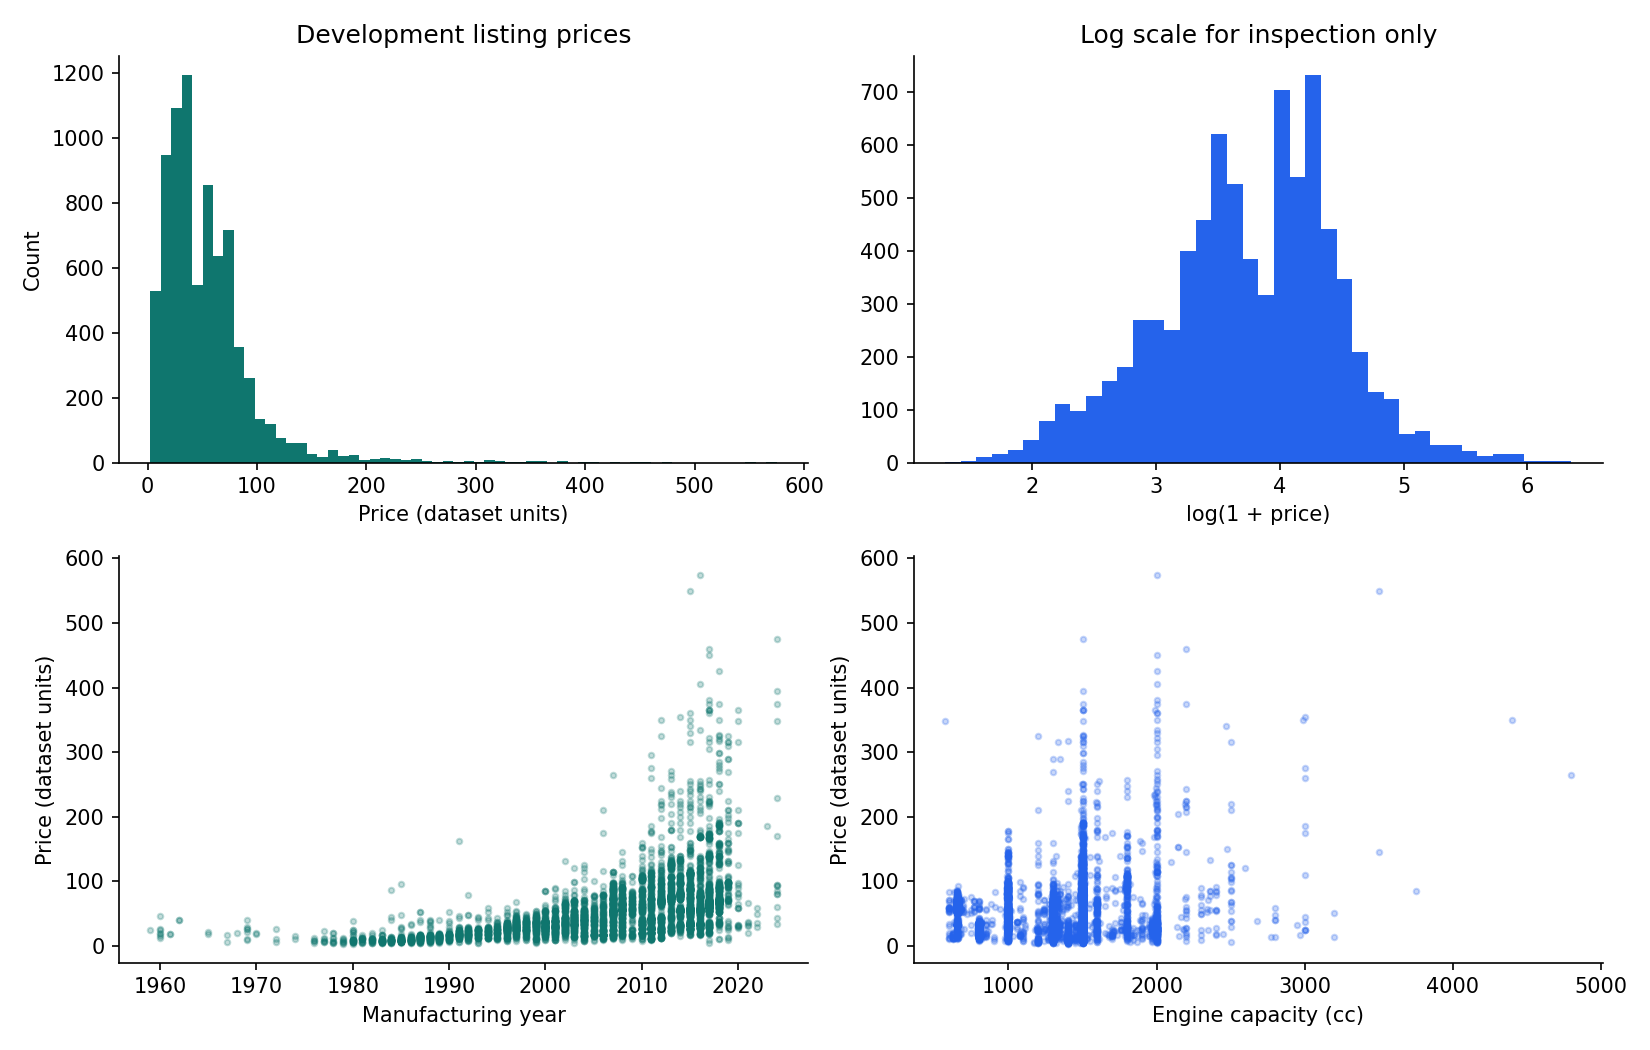

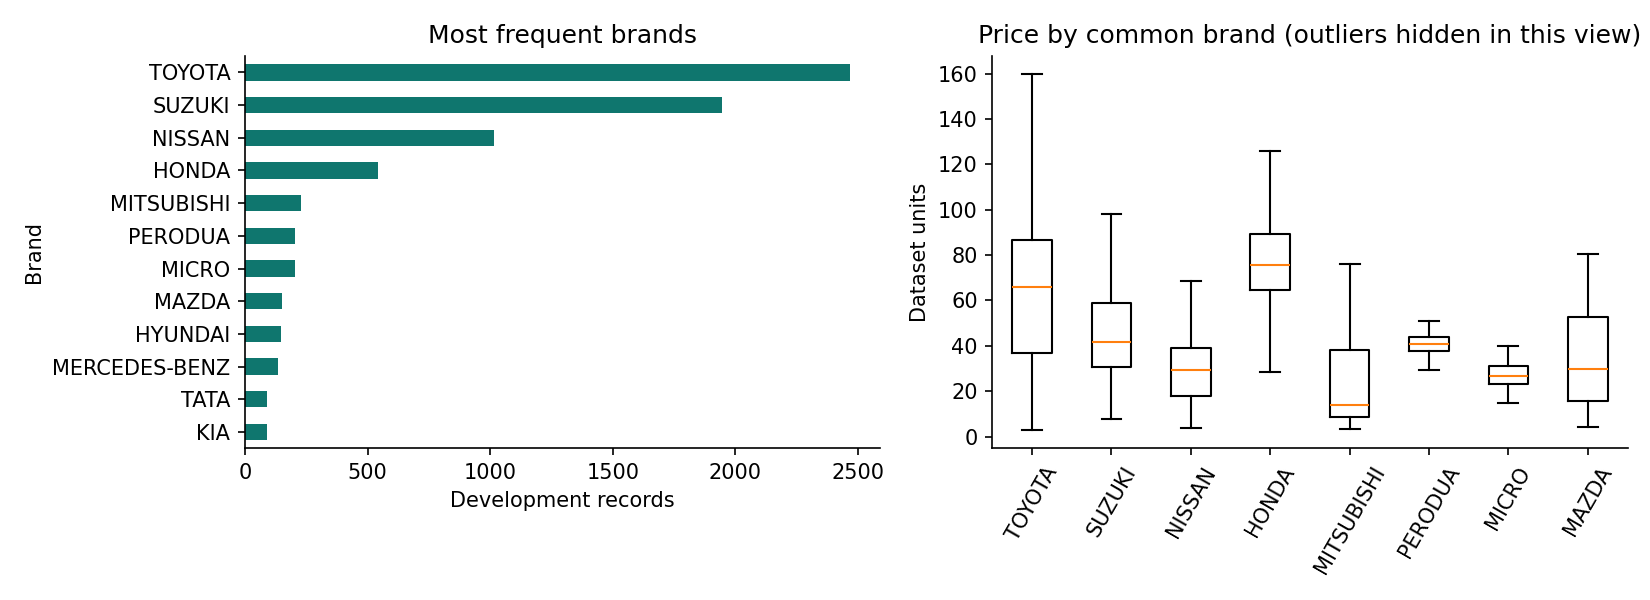

,YOM,Engine (cc),Price
YOM,1.000000,-0.404533,0.510366
Engine (cc),-0.404533,1.000000,0.200402
Price,0.510366,0.200402,1.000000


,count,median,mean
Fuel Type,,,
Diesel,483,24.50000,41.102591
Electric,57,54.40625,85.231937
Hybrid,994,73.80000,82.317342
Petrol,6277,38.25000,49.530180


,count,median,mean
Gear,,,
Automatic,5041,61.25,69.587872
Manual,2770,22.75,24.058732


,count,median,mean
Condition,,,
NEW,77,30.000000,61.650048
USED,7734,43.315972,53.360240


,count,median,mean
AIR CONDITION,,,
Available,7658,43.775,54.126950
Not_Available,153,13.000,19.156624


In [5]:
eda = development_eda(RUN_DIR)
display(pd.Series(eda))
display(train[NUMERIC + ["Price"]].describe().T)
display(train[CATEGORICAL].nunique().rename("Distinct development categories").to_frame())
display(Image(filename=str(RUN_DIR / "figures/development_eda.png")))
display(Image(filename=str(RUN_DIR / "figures/development_categories.png")))
display(train[NUMERIC + ["Price"]].corr())
for column in ["Fuel Type", "Gear", "Condition", "AIR CONDITION"]:
    display(train.groupby(column).Price.agg(["count", "median", "mean"]))


## 6. Model and preprocessing choices
- **Median baseline:** a constant prediction establishes a minimum useful reference.
- **Ridge:** regularized additive effects; numeric scaling and one-hot categories.
- **Random Forest:** nonlinear bagging baseline tied to the earlier activity.
- **XGBoost:** regularized histogram gradient boosting, also tied to the activity.
- **CatBoost:** categorical boosting suited to sparse, high-cardinality vehicle names.

Numeric imputation, scaling and one-hot vocabularies are learned within each training fold. One-hot encoders ignore unknown categories so validation can proceed. CatBoost receives named string categories, fills missing categories with a sentinel and learns numeric medians within its pipeline. CatBoost uses CPU Plain boosting for practical runtime; its categorical processing remains native. No manual full-dataset target encoding is used.

References: [Ridge](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression), [Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forest), [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html), [CatBoost categorical processing](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic).

In [6]:
display(pd.DataFrame([{"model": name, "reference_settings": REFERENCE_PARAMS[name], "candidate_count": len(candidate_parameters(name))} for name in NAMES]))
# Show the actual fitted-pipeline construction used throughout the study.
display(make_model("Ridge"))
display(make_model("CatBoost"))

,model,reference_settings,candidate_count
0,Median,{},1
1,Ridge,{'alpha': 10.0},5
2,Random Forest,"{'n_estimators': 150, 'max_depth': 18, 'min_sa...",8
3,XGBoost,"{'n_estimators': 300, 'learning_rate': 0.05, '...",10
4,CatBoost,"{'iterations': 600, 'depth': 6, 'learning_rate...",10


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['YOM', 'Engine (cc)']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(dtype=<class 'numpy.float32'>,
                                                                                 handle_unknown='ignore'))]),
                                                  ['Brand', 'Model', 'Gear',
                                                   'Fuel Type', 'Town',
                                                   'Leasing', 'Condition',
                                                   'AIR CONDITION',
                                                   'POWER STEERING',
                                                   'POWER MIRROR',
                                                   'POWER WINDOW'])])),
                ('regressor',
                 Ridge(alpha=10.0, max_iter=5000, solver='lsqr', tol=1e-05))])

Pipeline(steps=[('preprocessor', CatFrame()),
                ('regressor',
                 CatBoostRegressor(allow_writing_files=False, boosting_type='Plain', cat_features=['Brand', 'Model', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW'], depth=6, iterations=600, l2_leaf_reg=5.0, learning_rate=0.05, loss_function='RMSE', random_seed=42, thread_count=2, verbose=False))])

## 7. Small local pilot and resource check
Before the complete search, fit each reference model on 2,000 development-training rows and score 500 separate development-validation rows from the first grouped fold. Pilot scores are timing diagnostics and do not select a model.

Sample process resident memory and available system memory every 50 ms. RSS includes Python and loaded libraries; it is not incremental estimator memory or total system memory. Full search stops after a completed checkpoint if sampled RSS exceeds 2.5 GiB or available RAM falls below 512 MiB. Adjusting the approved design requires review rather than automatic fallback.

In [7]:
pilot_result = pilot(RUN_DIR)
display(pd.DataFrame(pilot_result["records"]))
print("Rough projected CV time (minutes):", round(pilot_result["projected_cv_seconds"]/60, 1))
print(pilot_result["estimate_note"])

,model,training_rows,validation_rows,seconds,peak_rss_mb,min_available_mb,MAE,RMSE,R2
0,Median,2000,500,0.115158,170.480469,1394.687500,39.626461,68.271413,-0.048069
1,Ridge,2000,500,0.048391,170.625000,1393.078125,19.702795,40.084642,0.638700
2,Random Forest,2000,500,3.406846,179.929688,1390.882812,12.579093,29.230325,0.807877
3,XGBoost,2000,500,0.697885,181.402344,1388.898438,11.112885,25.861402,0.849611
4,CatBoost,2000,500,19.252374,192.691406,1290.656250,11.280576,24.100722,0.869391


Rough projected CV time (minutes): 59.1
Rough linear row scaling from reference configurations; deeper trees can cost more.


## 8. Explicit baseline training
The following cell actually fits all five reference pipelines on the first grouped fold and reports validation errors. It offers a readable single-fold demonstration before the systematic search. These are development scores, not final test results.

In [8]:
a, b = folds[0]
baseline_records = []
for name in NAMES:
    baseline = make_model(name)
    start = time.perf_counter()
    with threadpool_limits(limits=2):
        baseline.fit(data.iloc[dev[a]][FEATURES], data.Price.iloc[dev[a]])
    elapsed = time.perf_counter() - start
    prediction = baseline.predict(data.iloc[dev[b]][FEATURES])
    baseline_records.append({"model": name, "fit_seconds": elapsed, **metrics(data.Price.iloc[dev[b]], prediction)})
    del baseline
display(pd.DataFrame(baseline_records))
pd.DataFrame(baseline_records).to_csv(RUN_DIR / "notebook_baselines.csv", index=False)

,model,fit_seconds,MAE,RMSE,R2
0,Median,0.142070,29.532304,47.481990,-0.061992
1,Ridge,0.096512,10.882416,22.649563,0.758352
2,Random Forest,14.676451,5.925926,14.430860,0.901905
3,XGBoost,1.347906,6.919717,14.728783,0.897813
4,CatBoost,18.014800,6.865135,13.233823,0.917504


## 9. Bounded hyperparameter study
Use five Ridge alphas; eight RF configurations; ten XGBoost configurations; ten CatBoost configurations; and one median baseline. This is 34 configurations and 170 grouped fold fits. Candidate sampling uses seed 42 and includes the original RF/XGBoost parameter sets.

Depth and leaf controls limit tree complexity. Learning rate and tree count control boosting contributions. Sampling and L1/L2 penalties regularize XGBoost; CatBoost depth and L2 leaf regularization are varied. Ridge alpha controls coefficient shrinkage. Search spaces are deliberately bounded for 8 GB RAM and four logical CPUs. Fixed boosting rounds avoid an additional early-stopping split.

MAE is primary; RMSE, R² and fit time are retained. Every completed fold is saved. The best configuration per family minimizes mean CV MAE. Among family winners within 1% of the lowest MAE, choose the lowest measured mean fold fit time. This predeclared practical tie rule uses no test scores. CV fold standard deviations are descriptive variability, not confidence intervals; selected CV scores also reflect search optimism.
`tune()` builds a fresh pipeline for each candidate/fold, fits it on that fold's development-training rows, predicts its validation rows and records all three metrics plus fit time. Imputers, scaling, one-hot vocabularies and CatBoost's categorical processing are therefore learned without validation or test targets. Five scores are aggregated per candidate; family winners and the final selection are recorded before `evaluate()` can inspect test performance.

The table below contains all 34 candidate summaries followed by the best configuration for each family. The 170 original per-fold progress lines are archived outside the notebook; the measured tables and original selection output are unchanged.


In [9]:
selection = tune(RUN_DIR)
cv_results = pd.DataFrame(json.loads((RUN_DIR / "cv_results.json").read_text()))
display(cv_results.drop(columns="params").sort_values("MAE_mean").reset_index(drop=True))
display(pd.DataFrame(selection["best_by_model"])[["model", "MAE_mean", "MAE_std", "RMSE_mean", "R2_mean", "seconds_mean", "params"]])
print("Frozen winner:", selection["winner"])
assert selection["test_used_for_selection"] is False

,model,candidate,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,seconds_mean,seconds_std
0,Random Forest,6,5.600238,0.523755,14.318491,2.410943,0.892483,0.024440,36.957657,0.337066
1,Random Forest,4,5.606470,0.513555,14.353505,2.474582,0.891941,0.025458,18.538527,0.639465
2,Random Forest,0,5.879085,0.539053,14.468619,2.449754,0.890118,0.025799,14.227032,0.655077
3,Random Forest,2,5.904552,0.538750,14.317500,2.558960,0.892472,0.026409,22.074579,0.636714
4,Random Forest,3,6.180283,0.543944,15.118413,2.609127,0.880286,0.027142,9.675238,0.183547
5,Random Forest,7,6.213474,0.586043,15.122982,2.580122,0.880234,0.026543,22.025302,0.532990
6,XGBoost,9,6.377002,0.497782,13.799796,1.861861,0.900434,0.014433,1.524553,0.072821
7,XGBoost,1,6.389018,0.532790,13.730024,1.949490,0.901446,0.015645,2.036089,0.075403
8,XGBoost,3,6.401704,0.524925,13.618589,1.853916,0.903001,0.014624,0.882111,0.022230
9,XGBoost,0,6.586094,0.538222,14.033877,2.038007,0.897036,0.017002,1.199174,0.054096


,model,MAE_mean,MAE_std,RMSE_mean,R2_mean,seconds_mean,params
0,Median,28.360876,1.344170,44.891280,-0.056035,0.069026,{}
1,Ridge,8.524719,0.660667,19.703819,0.796360,0.154048,{'alpha': 0.1}
2,Random Forest,5.600238,0.523755,14.318491,0.892483,36.957657,"{'n_estimators': 300, 'min_samples_split': 4, ..."
3,XGBoost,6.377002,0.497782,13.799796,0.900434,1.524553,"{'subsample': 0.85, 'reg_lambda': 2.0, 'reg_al..."
4,CatBoost,6.871643,0.602783,14.152519,0.894788,27.309678,"{'learning_rate': 0.05, 'l2_leaf_reg': 10.0, '..."


Frozen winner: Random Forest


## 10. Final refitting, export and reserved-test evaluation
Only after selection is recorded, refit each family's chosen configuration on all development rows. Evaluate all five on the reserved grouped test set for reporting, while retaining the CV-selected winner regardless of the test ranking.

MAE is average absolute error; RMSE penalizes large errors more heavily; R² compares against predicting the test-set mean. R² is not an accuracy percentage. Fit time is measured on this laptop. Artifact size includes the saved pipeline and any companion native exports, so it measures the submitted inference bundle rather than a library-independent model representation.

Every model is exported and reloaded; predictions on all test observations must agree. XGBoost also receives native UBJSON export, and CatBoost native CBM export. Pickle/joblib files require a trusted source and matching environment.
`evaluate()` reads the saved CV selection and calls `make_model()` with each family's chosen parameters. After a development-only refit, it records held-out predictions and errors, saves the fitted pipeline, reloads it and checks prediction equality on every test row. It then runs the separate fixed-reference split study and selected-model interpretation. Returning test scores does not revise the earlier CV decision. The repeated progress JSON is archived in verification; the original final table and comparison chart are retained below.


,model,MAE,RMSE,R2,seconds,prediction_seconds,artifact_bytes,reload_verified
0,Median,27.885527,44.034588,-0.060243,0.082766,0.021764,10809,True
1,Ridge,8.413340,21.486517,0.747565,0.202515,0.022674,24296,True
2,Random Forest,4.909325,19.016990,0.802257,52.429149,0.160997,21494573,True
3,XGBoost,5.985133,19.507799,0.791918,1.753027,0.052317,1253150,True
4,CatBoost,6.574668,19.940613,0.782583,28.656349,0.031330,3976585,True


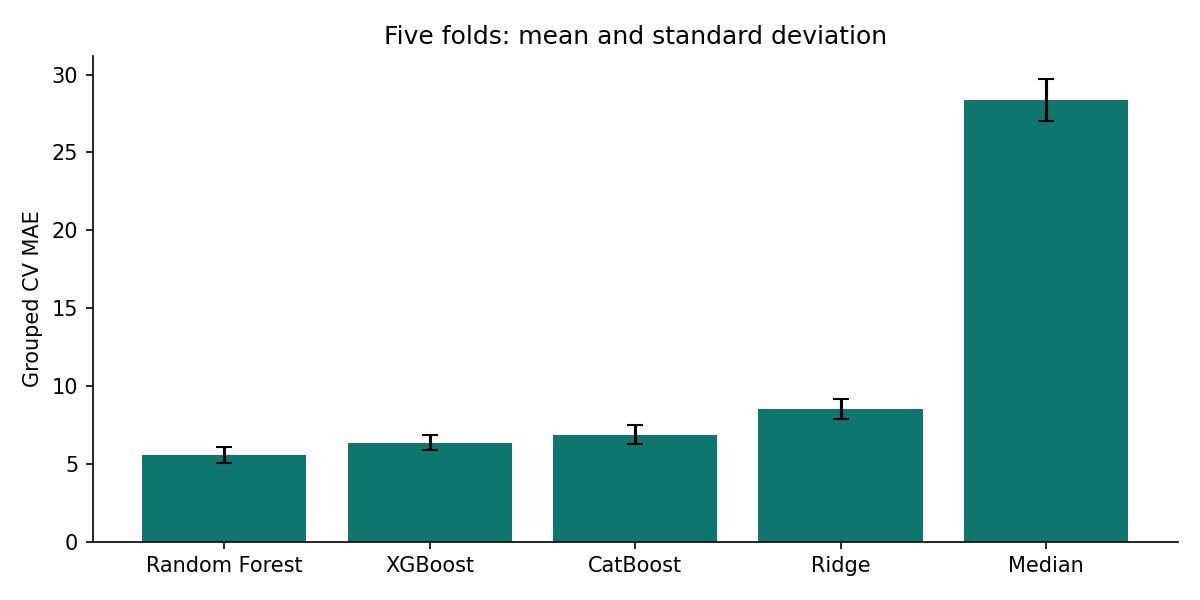

In [10]:
test_results = evaluate(RUN_DIR)
display(pd.DataFrame(test_results)[["model", "MAE", "RMSE", "R2", "seconds", "prediction_seconds", "artifact_bytes", "reload_verified"]])
display(Image(filename=str(RUN_DIR / "figures/cv_comparison.png")))

## 11. Clearly separated random-split sensitivity study
The secondary study uses the old 80/20 shuffled split with seed 42. To compare the evaluation designs under fixed model settings, **both** grouped and random sensitivity runs use identical fixed reference configurations, not the configurations selected using grouped development targets. There is no random-split tuning and these scores cannot select the winner.

The random partition has 297 test records sharing all predictors with training. Compare fixed grouped and random scores with attention to differing test populations. Historical activity scores (RF 5.8880 / 21.1365 / 0.8119; XGBoost 6.9775 / 21.3378 / 0.8083 for MAE/RMSE/R²) are background evidence. Similar random results may support reproducibility; differences from primary grouped scores do not establish algorithmic improvement. Historical Colab timings are not compared as laptop speed benchmarks.

In [11]:
sensitivity = pd.DataFrame(json.loads((RUN_DIR / "sensitivity.json").read_text()))
display(sensitivity[["protocol", "model", "MAE", "RMSE", "R2", "seconds", "test_rows", "overlap_rows"]])

,protocol,model,MAE,RMSE,R2,seconds,test_rows,overlap_rows
0,grouped_fixed,Median,27.885527,44.034588,-0.060243,0.082098,1959,0
1,grouped_fixed,Ridge,9.803159,23.651964,0.694119,0.099677,1959,0
2,grouped_fixed,Random Forest,5.173016,19.131825,0.799862,18.149403,1959,0
3,grouped_fixed,XGBoost,6.067066,19.554787,0.790915,1.423208,1959,0
4,grouped_fixed,CatBoost,6.644818,20.010969,0.781046,20.052045,1959,0
5,random_fixed,Median,29.602104,50.275347,-0.064132,0.084961,1954,297
6,random_fixed,Ridge,10.605210,27.340703,0.685294,0.106198,1954,297
7,random_fixed,Random Forest,5.888033,21.136470,0.811917,18.689118,1954,297
8,random_fixed,XGBoost,6.926460,21.363429,0.807856,1.361428,1954,297
9,random_fixed,CatBoost,7.323115,21.478569,0.805779,18.973292,1954,297


## 12. Residuals, category errors and interpretation
Inspect actual-versus-predicted values and residuals for the frozen winner. Price bands are fixed at 0–25, 25–50, 50–100, 100–200 and 200+ dataset units. Their counts matter when interpreting errors in rare expensive vehicles.

Permutation importance shuffles each original input column five times and measures the increase in test MAE. This is post-selection explanation only and does not drive model revision. Related attributes, such as brand and model, may share importance; importance is not causal evidence. Category slices use training frequencies: unseen, 1–4 observations, and at least five. These are descriptive slices with limited sample sizes.

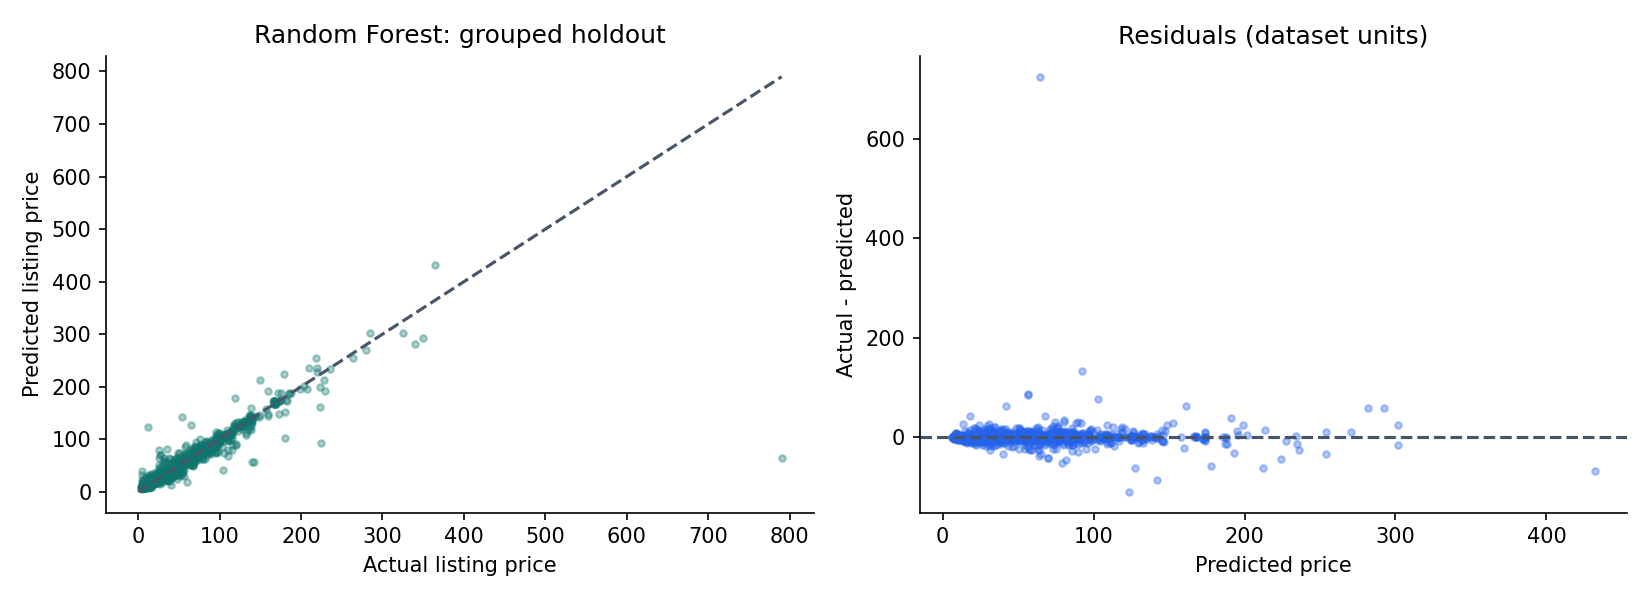

,price_band,count,MAE,mean_residual
0,0-25,433,3.524015,-2.385294
1,25-50,657,3.801975,-0.356121
2,50-100,694,4.061065,-0.009462
3,100-200,155,9.256118,3.099789
4,200+,20,67.024758,50.178644


,feature,group,count,MAE,RMSE,R2
0,Brand,rare_1_to_4,7,17.073709,20.899070,0.911703
1,Brand,seen_5_plus,1952,4.865703,19.009905,0.800869
2,Model,unseen,182,9.450026,16.852057,0.894678
3,Model,rare_1_to_4,231,11.349778,50.686483,0.467996
4,Model,seen_5_plus,1546,3.412461,6.399344,0.967959
5,Town,unseen,1,0.500930,0.500930,NaN
6,Town,rare_1_to_4,11,2.413732,3.308118,0.978225
7,Town,seen_5_plus,1947,4.925689,19.073880,0.801782


,row_id,actual,prediction,residual,absolute_error,price_band,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Town,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW
0,8402,790.00,64.447609,725.552391,725.552391,200+,TOYOTA,LEXUS 600HL,2011,600.0,Automatic,Hybrid,Katunayake,No Leasing,USED,Available,Available,Available,Available
1,4035,225.00,92.185068,132.814932,132.814932,200+,SUBARU,STI 12,2015,2000.0,Manual,Petrol,Colombo,No Leasing,USED,Available,Available,Available,Available
2,1478,12.60,123.456895,-110.856895,110.856895,0-25,MAZDA,6,2013,2000.0,Automatic,Petrol,Anuradapura,No Leasing,USED,Available,Available,Available,Available
3,8364,53.75,141.695250,-87.945250,87.945250,50-100,TOYOTA,IST,2023,1395.0,Automatic,Petrol,Ratnapura,No Leasing,USED,Available,Available,Available,Available
4,3929,142.00,56.457987,85.542013,85.542013,100-200,PEUGEOT,508,2011,1600.0,Automatic,Petrol,Colombo,No Leasing,USED,Available,Available,Available,Available
5,3930,140.00,56.457987,83.542013,83.542013,100-200,PEUGEOT,508,2011,1600.0,Automatic,Petrol,Colombo,No Leasing,USED,Available,Available,Available,Available
6,1771,180.00,102.955983,77.044017,77.044017,100-200,MERCEDES-BENZ,S350,2005,3000.0,Automatic,Petrol,Ja-Ela,No Leasing,USED,Available,Available,Available,Available
7,130,364.50,432.422940,-67.922940,67.922940,200+,BMW,530E,2017,2000.0,Automatic,Petrol,Colombo,No Leasing,USED,Available,Available,Available,Available
8,9713,64.75,127.535515,-62.785515,62.785515,50-100,VOLKSWAGEN,LEAF POLO E-UP,2019,1500.0,Automatic,Electric,Piliyandala,No Leasing,USED,Available,Available,Available,Available
9,155,149.50,212.274422,-62.774422,62.774422,100-200,BMW,MINI COOPER,2020,1200.0,Automatic,Petrol,Colombo,No Leasing,USED,Available,Available,Available,Available


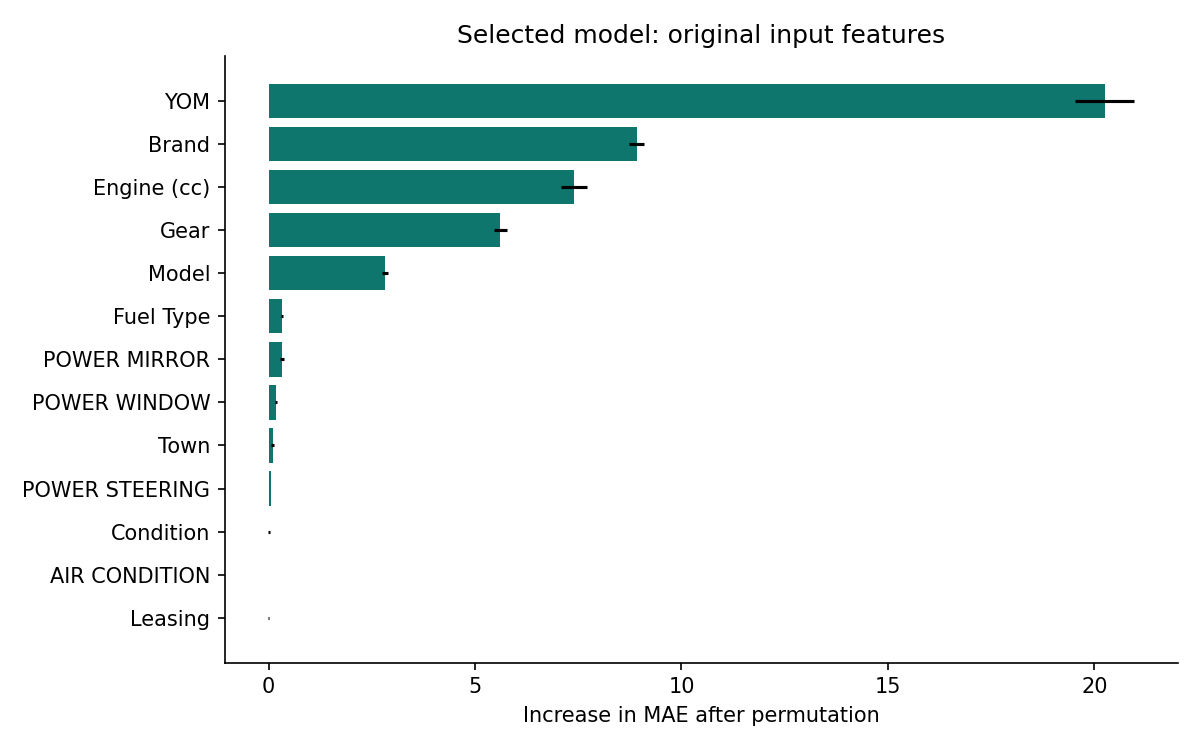

In [12]:
display(Image(filename=str(RUN_DIR / "figures/test_residuals.png")))
display(pd.read_csv(RUN_DIR / "price_band_errors.csv"))
display(pd.DataFrame(json.loads((RUN_DIR / "category_errors.json").read_text())))
display(pd.read_csv(RUN_DIR / "largest_errors.csv"))
display(Image(filename=str(RUN_DIR / "figures/permutation_importance.png")))

## 13. Single-observation inference from the exported model
Use the first observation returned by the grouped holdout as a fixed example. It was not selected for a favourable error. The exported model receives only the 13 predictor values. Compare its prediction with the advertised price and verify equality with the saved evaluation prediction. A held-out category may be unseen during training; this is part of the evaluation, not evidence that the app should offer unsupported choices.

In [13]:
import joblib
example = json.loads((RUN_DIR / "heldout_example.json").read_text())
slug = selection["winner"].lower().replace(" ", "_")
exported_model = joblib.load(RUN_DIR / "models" / slug / "pipeline.joblib")
single = data.iloc[[example["row_id"]]][FEATURES]
reloaded_prediction = float(exported_model.predict(single)[0])
assert np.isclose(reloaded_prediction, example["prediction"])
display(single.T)
display(pd.Series({"actual": example["actual"], "prediction": reloaded_prediction, "absolute_error": example["absolute_error"]}))

,11
Brand,AUDI
Model,A3
YOM,2018
Engine (cc),1000.0
Gear,Automatic
Fuel Type,Petrol
Town,Kandy
Leasing,No Leasing
Condition,USED
AIR CONDITION,Available


actual            139.000000
prediction        141.456916
absolute_error      2.456916
dtype: float64

## 14. Discussion and limitations
Random Forest was selected before holdout evaluation because it had the lowest grouped CV MAE (5.6002, fold SD 0.5238). Its selected settings were 300 trees, unrestricted maximum depth, minimum split size 4, minimum leaf size 2 and feature fraction 0.8. The leaf restrictions still limit very small terminal groups. No other family was within the predeclared 1% MAE tolerance, so the speed tie rule did not alter selection.

On the 1,959-row grouped holdout, RF achieved MAE 4.9093, RMSE 19.0170 and R² 0.8023. XGBoost achieved MAE 5.9851, RMSE 19.5078 and R² 0.7919; CatBoost achieved MAE 6.5747, RMSE 19.9406 and R² 0.7826. Ridge improved substantially on the median baseline but did not match the tree ensembles. These findings answer the first research question for this bounded study; they do not establish that RF is universally superior. XGBoost had the lowest CV RMSE and a much shorter final fit (1.75 s versus RF's 52.43 s), so the primary metric affects the practical conclusion.

The 170 grouped CV fits consumed 25.37 minutes of summed fit time, excluding pilot, notebook setup, final refits and sensitivity work. Peak sampled CV process RSS was 302.1 MiB. The small pilot's linear scaling estimate was conservative; no resource threshold was reached and local training was practical.

The separate fixed-parameter sensitivity study produced lower MAE on its grouped partition than on its random partition. The partitions contain different observations, so this does not prove that overlap is harmless or quantify its causal effect. The random RF results reproduce the historical rounded activity metrics (5.8880 / 21.1365 / 0.8119). Newly fitted random XGBoost scored 6.9265 / 21.3634 / 0.8079, differing slightly from the historical 6.9775 / 21.3378 / 0.8083. Its exact cause was not established; the original model was trained in a different environment. The recorded historical scores remain unchanged and the new values are reported separately.

Prediction errors remain uneven. The 20 held-out listings above 200 dataset units had MAE 67.02, compared with 3.52–4.06 in the three bands below 100. This explains why RMSE is much larger than overall MAE. Manufacturing year, brand and engine capacity had the largest permutation importance. Shuffling related inputs independently can create implausible combinations, so this explanation is conditional and not causal. The fixed held-out example was an Audi A3, 2018: advertised price 139.00, prediction 141.46, absolute error 2.46 units. Its favourable error was not a selection criterion.

Limitations include historical advertisements, unverified transaction outcomes, unresolved price units, year-derived mileage, rare model categories, repeated attributes without vehicle identifiers, possible near-duplicates, and a short collection period. Existing exploration means the data is not independent external validation. Finite searches and one grouped holdout limit certainty; no significance claim, calibrated prediction interval or future-market result is established.

The standard workflow preserves the grouped test set for reporting, but human knowledge of earlier activity results cannot be undone. The random sensitivity study is secondary. Changes motivated by final test errors must be documented as a new exploratory experiment, rather than used to improve and re-report this same test result.

## 15. Conclusion
Within this dataset and bounded search, Random Forest gave the lowest grouped CV MAE and remained the selected model for single-listing inference. XGBoost offered a much faster fit and lower CV RMSE, while native categorical processing in CatBoost did not improve MAE in the tested configurations. The main contribution is the consistent, group-aware comparison and error analysis, rather than a claim of universal algorithmic superiority. Large errors for expensive vehicles and uncertain source units limit practical use.

## 16. Academic acknowledgement and references
This implementation was developed with OpenAI Codex assistance for code, experiment execution, documentation and verification. The student must review the work, explain the methodology, and adapt this statement to institutional AI-use rules. This statement does not assert compliance with an unknown university policy.

References: dataset by Prasad Nirmal linked above; [scikit-learn grouped CV](https://scikit-learn.org/stable/modules/cross_validation.html); [pipeline leakage prevention](https://scikit-learn.org/stable/common_pitfalls.html); [CatBoost documentation](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor); [XGBoost model IO](https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html). The previous class activity is acknowledged as the origin of the topic and data-quality findings.

### Method references

Hoerl, A. E. and Kennard, R. W. (1970). [Ridge Regression: Biased Estimation for Nonorthogonal Problems](https://www.tandfonline.com/doi/abs/10.1080/00401706.1970.10488634). Technometrics, 12(1), 55–67.

Breiman, L. (2001). [Random Forests](https://doi.org/10.1023/A:1010933404324). Machine Learning, 45, 5–32.

Chen, T. and Guestrin, C. (2016). [XGBoost: A Scalable Tree Boosting System](https://arxiv.org/abs/1603.02754).

Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V. and Gulin, A. (2018). [CatBoost: unbiased boosting with categorical features](https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html). NeurIPS 31. Our CPU Plain boosting configuration is not a reproduction of all settings in this paper.
